# Spindle quick start: build both indexes on one section and search them

This notebook takes one spatial-omics section (an `.h5ad` with raw counts in `X` and cell centroids in
`obsm["spatial"]`), builds the two Spindle indexes on it and runs the three kinds of query:

| Query | What you give | Index searched |
|---|---|---|
| 1. Whole tile | a tile's covariance over all index genes | **Spindle** |
| 2. Gene set from a tile | a tile's covariance, cut to a gene set | **Spindle partial** |
| 3. Gene list | gene names only (a co-expression template) | **Spindle partial** |

Every query is also answered by **Spindle-naive**, the exact scan, so you can see how close Spindle's answer is to
the exact one. Steps:

1. tile the section (quadtree, at most 200 cells per tile) and compute every tile's shrunk gene covariance;
2. hold out some tiles as queries, build the layout (covariance niches, gene blocks) on the rest;
3. build Spindle-naive, Spindle and Spindle partial;
4. run the three queries and map the tiles Spindle returns.

Set the parameters in the next cell and run all cells. A section of ~100k cells takes a few minutes and a few GB of
memory.

In [1]:
# ---- parameters ------------------------------------------------------------------------------------------------
DATASET = "dataset/xenium/xenium_human_skin_melanoma.h5ad"  # .h5ad path (relative paths: from the repository root)
MAX_GENES = 800       # the index keeps the top-variance min(MAX_GENES, n_genes) genes
N_HOLDOUT = 100       # tiles held out of the index, used as queries
SEED = 0              # held-out split
GENE_LIST = ["CD68", "CD163", "CD14", "AIF1", "MNDA"]   # queries 2 and 3 (a myeloid program); edit for your panel
TOP = 10              # results shown per query
OUT_DIR = None        # a folder to save the layout and indexes (pickles), or None

In [2]:
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")       # tqdm, imported by umap
warnings.filterwarnings("ignore", message="n_jobs value .* overridden")  # umap with a fixed seed

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle

# the repository root: the first folder up from here that holds src/spindle_dev
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "spindle_dev").is_dir())
try:
    import spindle_dev as sd              # installed (pip install -e .)
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))
    import spindle_dev as sd
from spindle_dev.metrics import as_cov

path = Path(DATASET)
path = path if path.is_absolute() else ROOT / path
print("dataset:", DATASET)

dataset: dataset/xenium/xenium_human_skin_melanoma.h5ad


## 1. Tiles and covariances

`prepare_tiles` splits the section into quadtree tiles of at most 200 cells, keeps the most variable genes and
computes each tile's gene covariance, shrunk once (α = 0.1). Everything downstream uses these shrunk covariances.

In [3]:
t0 = time.time()
adata = sd.load_adata(path)
tiles, covs, genes = sd.prepare_tiles(adata, max_genes=MAX_GENES)
genes = np.asarray([str(g) for g in genes])
print(f"{adata.n_obs:,} cells, {len(tiles):,} tiles, {len(genes)} genes ({time.time() - t0:.0f} s)")

train, test = sd.split_tiles(len(tiles), seed=SEED, n_holdout=N_HOLDOUT)
train_tiles = [tiles[i] for i in train]
train_covs = [covs[i] for i in train]
print(f"{len(train):,} index tiles, {len(test)} held-out query tiles")

[2026-11-06 17:41:02,498] INFO spindle_dev.preprocessing: build_quadtree_tiles: dropping 19 low-density tile(s) (895 spots)


87,499 cells, 932 tiles, 382 genes (5 s)
832 index tiles, 100 held-out query tiles


## 2. Layout and the two indexes

`build_layout` groups the index tiles into covariance niches and orders the genes of each niche into blocks. On that
layout:

- **Spindle-naive** (`SpindleNaive`, `SpindleNaivePartial`) stores every tile's block logs and scans them all: exact,
  the reference.
- **Spindle** (`Spindle`) answers whole-tile queries from a layered DAG of block nodes per niche.
- **Spindle partial** (`SpindlePartial`) answers gene-set queries from nodes on dyadic gene intervals.

Both Spindle indexes are built from the Spindle-naive ones (same logs, nothing recomputed). `variance_quantiles` keeps
each gene's 90th-percentile variance beside the index, for gene-list queries (query 3).

In [4]:
t0 = time.time()
data = sd.build_layout(train_tiles, train_covs, genes, adata.n_obs)
labels = np.asarray(data.labels).astype(int)
print(f"layout: {len(set(labels.tolist()))} niches, "
      f"{np.mean([len(data.block_dict[k]) for k in data.block_dict]):.1f} gene blocks per niche ({time.time() - t0:.0f} s)")

t0 = time.time()
naive = sd.SpindleNaive(data, train_covs)
spindle = sd.Spindle.from_naive(naive, data)
t_whole = time.time() - t0
t0 = time.time()
naive_partial = sd.SpindleNaivePartial(data, train_covs)
spindle_partial = sd.SpindlePartial.from_naive_partial(naive_partial, data)
t_partial = time.time() - t0
omega = sd.variance_quantiles(train_covs)

MB = 1e6
print(f"Spindle          {spindle.n_nodes():>7,} nodes, {spindle.nbytes() / MB:7.2f} MB "
      f"({100 * spindle.nbytes() / spindle.naive_bytes:.1f} % of Spindle-naive's {spindle.naive_bytes / MB:.1f} MB), "
      f"built with Spindle-naive in {t_whole:.0f} s")
print(f"Spindle partial  {spindle_partial.n_nodes():>7,} nodes, {spindle_partial.nbytes() / MB:7.2f} MB "
      f"({100 * spindle_partial.nbytes() / spindle_partial.naive_bytes:.1f} % of Spindle-naive's "
      f"{spindle_partial.naive_bytes / MB:.1f} MB), built with Spindle-naive in {t_partial:.0f} s")

[2026-11-06 17:41:21,510] INFO spindle_dev.layout: Leiden resolution 0.20: 3 niches, sizes [375, 373, 84]
[2026-11-06 17:41:22,883] INFO spindle_dev.layout: Niche 0: 21 blocks
[2026-11-06 17:41:22,955] INFO spindle_dev.layout: Niche 1: 18 blocks
[2026-11-06 17:41:23,041] INFO spindle_dev.layout: Niche 2: 19 blocks


layout: 3 niches, 19.3 gene blocks per niche (19 s)


[2026-11-06 17:41:24,419] INFO spindle_dev.spindle: Niche 0: 375 tiles, 21 layers, 392 nodes, 0.3s
[2026-11-06 17:41:24,789] INFO spindle_dev.spindle: Niche 1: 373 tiles, 18 layers, 464 nodes, 0.4s
[2026-11-06 17:41:24,820] INFO spindle_dev.spindle: Niche 2: 84 tiles, 19 layers, 140 nodes, 0.0s
[2026-11-06 17:41:27,368] INFO spindle_dev.spindle_partial: Niche 0: 375 tiles, 693 intervals, 27912 nodes, 2.0s
[2026-11-06 17:41:29,556] INFO spindle_dev.spindle_partial: Niche 1: 373 tiles, 708 intervals, 29315 nodes, 2.2s
[2026-11-06 17:41:29,980] INFO spindle_dev.spindle_partial: Niche 2: 84 tiles, 697 intervals, 8464 nodes, 0.4s


Spindle              996 nodes,    1.72 MB (11.3 % of Spindle-naive's 15.2 MB), built with Spindle-naive in 2 s
Spindle partial   65,691 nodes,    2.11 MB (13.9 % of Spindle-naive's 15.2 MB), built with Spindle-naive in 5 s


### Plotting helpers

Each query gets a map of the section: cells in grey, every index tile as a faint outline, the tiles Spindle returns
filled by their score (darker = closer to the query), its top results outlined in black and the query tile (if any)
outlined in orange. Next to the map, the exact distances of Spindle's top results are compared with the exact top
results of Spindle-naive. Gene-set queries also show the query's gene correlations beside those of Spindle's best
match.

In [5]:
rng = np.random.default_rng(0)
cells_xy = np.asarray(adata.obsm["spatial"])[:, :2]
cells_xy = cells_xy[rng.choice(len(cells_xy), min(len(cells_xy), 100_000), replace=False)]
QUERY_COLOR = "#e8710a"


def rects(tile_list):
    return [Rectangle((t.bbox[0], t.bbox[1]), t.bbox[2] - t.bbox[0], t.bbox[3] - t.bbox[1]) for t in tile_list]


def show_map(ax, rows, scores, title, query_tile=None, top=TOP):
    # Spindle's returned tiles on the section, filled by score; top results outlined
    ax.scatter(cells_xy[:, 0], cells_xy[:, 1], s=0.05, c="#d0d0d0", rasterized=True, linewidths=0)
    ax.add_collection(PatchCollection(rects(train_tiles), facecolor="none", edgecolor="#e4e4e4", linewidth=0.3))
    order = np.argsort(scores)[::-1]           # draw the closest last, on top
    pc = PatchCollection(rects([train_tiles[r] for r in rows[order]]), cmap="Blues_r", edgecolor="none")
    pc.set_array(np.asarray(scores)[order])
    ax.add_collection(pc)
    ax.add_collection(PatchCollection(rects([train_tiles[r] for r in rows[:top]]), facecolor="none",
                                      edgecolor="black", linewidth=1.0))
    if query_tile is not None:
        ax.add_collection(PatchCollection(rects([query_tile]), facecolor="none", edgecolor=QUERY_COLOR, linewidth=2))
    plt.colorbar(pc, ax=ax, shrink=0.6, label="Spindle score (lower = closer)")
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.invert_yaxis()
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=10)


def show_ranks(ax, d_exact, rows, top=TOP):
    # the exact distances of Spindle's top results (sorted) against those of the exact top results
    k = min(top, len(rows))
    r = np.arange(1, k + 1)
    ax.plot(r, np.sort(d_exact)[:k], "-o", color="#9e9e9e", ms=4, lw=1.5, label=f"exact top {k} (Spindle-naive)")
    ax.plot(r, np.sort(d_exact[rows[:k]]), "-o", color="#1f5fa8", ms=4, lw=1.5, label=f"Spindle's top {k}")
    ax.set_xlabel("k-th closest of the top results")
    ax.set_ylabel("exact distance to the query")
    ax.set_xticks(r)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=1, fontsize=8)


def show_query(rows, scores, d_exact, title, query_tile=None):
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [2, 1]})
    show_map(ax0, rows, scores, title, query_tile=query_tile)
    show_ranks(ax1, d_exact, rows)
    fig.tight_layout()
    plt.show()


def show_corr_pair(cov_q, cov_best, names, q_title):
    # gene correlations of the query beside those of Spindle's best match
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.6), layout="constrained")
    show_corr(axes[0], cov_q, names, q_title)
    im = show_corr(axes[1], cov_best, names, "Spindle's best match")
    fig.colorbar(im, ax=axes, shrink=0.8, label="gene correlation")
    plt.show()


def show_corr(ax, cov, names, title):
    sdv = np.sqrt(np.diag(cov))
    im = ax.imshow(cov / np.outer(sdv, sdv), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(names)), names, rotation=90, fontsize=7)
    ax.set_yticks(range(len(names)), names, fontsize=7)
    ax.set_title(title, fontsize=10)
    return im


def summary(name, rows, d_exact, sec, stats, top=TOP):
    k = min(top, len(rows))
    exact_top = np.argsort(d_exact, kind="stable")[:k]
    excess = 100 * (d_exact[rows[:k]].mean() / d_exact[exact_top].mean() - 1)
    print(f"{name}: Spindle returned {len(rows)} of {len(d_exact):,} tiles in {1e3 * sec:.2f} ms "
          f"(radius {stats['radius']:.3f}); {len(set(rows[:k].tolist()) & set(exact_top.tolist()))} of the exact "
          f"top {k} in its top {k}; its top {k} is {excess:.1f} % farther from the query than the exact top {k}")

## 3. Query 1: a whole tile

The query is a held-out tile's covariance over all index genes. `Spindle.search` returns index rows (best first),
their scores and the time taken; the exact distances d_B to every tile come from Spindle-naive.

Whole tile: Spindle returned 104 of 832 tiles in 6.95 ms (radius 0.189); 7 of the exact top 10 in its top 10; its top 10 is 1.9 % farther from the query than the exact top 10


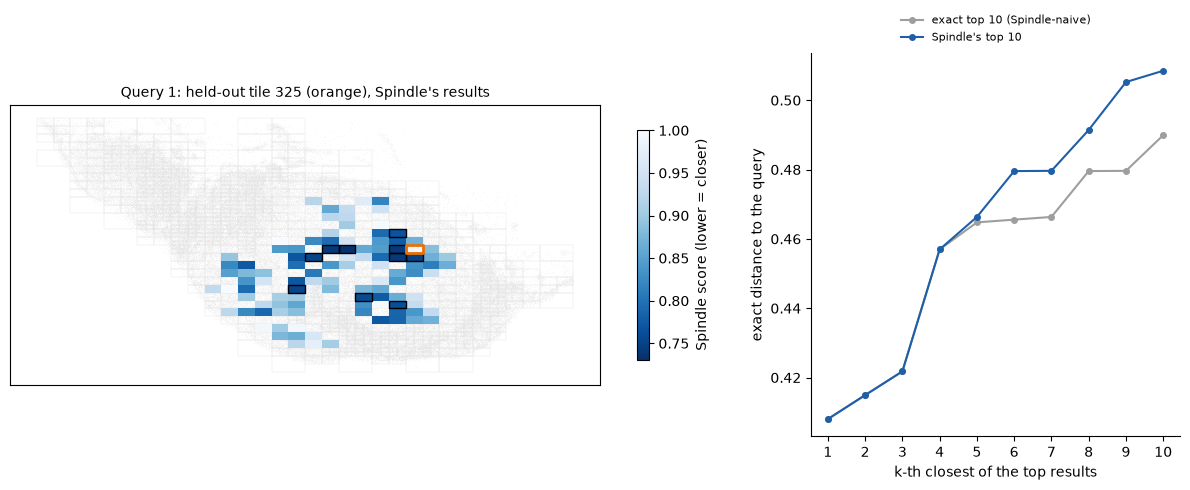

In [6]:
q_tile = int(test[0])
query = covs[q_tile]

rows1, scores1, sec1 = spindle.search(query)
d1 = naive.distances(naive.query_vectors(query))          # exact d_B to every index tile (reference)
summary("Whole tile", rows1, d1, sec1, spindle.last_stats)

show_query(rows1, scores1, d1, f"Query 1: held-out tile {q_tile} (orange), Spindle's results",
           query_tile=tiles[q_tile])

## Gene set for queries 2 and 3

`gene_indices` turns gene names into index positions; names not among the index genes are dropped and reported. If
fewer than two of `GENE_LIST` are in the index, the notebook falls back to the first genes of one gene block.

In [7]:
idx, found, missing = sd.gene_indices(genes, GENE_LIST)
if missing:
    print("not among the index genes:", missing)
if len(idx) < 2:
    k0 = int(labels[0])
    s, e = data.block_dict[k0][0]
    idx = np.asarray(data.perm_list[k0])[s:min(e, s + 8)]
    found = genes[idx].tolist()
    print("fewer than 2 listed genes in the index; using the first genes of a gene block instead")
print(f"gene set ({len(idx)} genes):", found)

gene set (5 genes): ['CD68', 'CD163', 'CD14', 'AIF1', 'MNDA']


## 4. Query 2: a gene set from a tile

The query is a held-out tile's covariance cut to the gene set (`tile_query`): which index tiles co-vary these genes
as this tile does? As query tile we take a held-out tile where the listed genes are active: the one at the 90th
percentile of their summed variance (the most extreme tile tends to be an outlier with few close matches).
`SpindlePartial.search` answers it; Spindle-naive's exact distances d_B^S are the reference.

Gene set from a tile: Spindle returned 36 of 832 tiles in 1.04 ms (radius 0.304); 8 of the exact top 10 in its top 10; its top 10 is 2.6 % farther from the query than the exact top 10


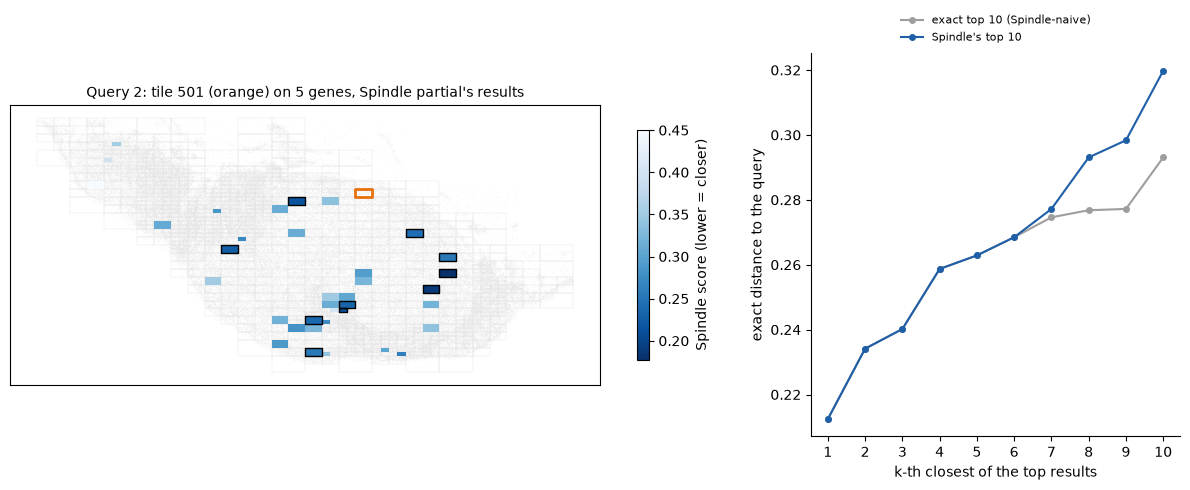

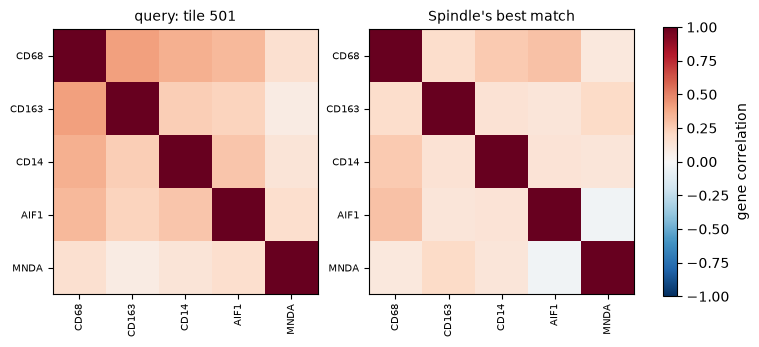

In [8]:
gene_var = np.array([np.trace(as_cov(covs[t])[np.ix_(idx, idx)]) for t in test])
q2 = int(test[np.argsort(gene_var)[int(0.9 * (len(test) - 1))]])
cov2, idx2 = sd.tile_query(covs[q2], idx)

rows2, scores2, sec2 = spindle_partial.search(cov2, idx2)
d2 = naive_partial.distances(cov2, idx2)                  # exact d_B^S to every index tile (reference)
summary("Gene set from a tile", rows2, d2, sec2, spindle_partial.last_stats)

show_query(rows2, scores2, d2, f"Query 2: tile {q2} (orange) on {len(idx2)} genes, Spindle partial's results",
           query_tile=tiles[q2])
show_corr_pair(cov2, as_cov(train_covs[rows2[0]])[np.ix_(idx2, idx2)], genes[idx2], f"query: tile {q2}")

## 5. Query 3: a gene list alone

With no tile in hand, `template_query` builds the query from the gene names alone: every pair of listed genes
correlated at ρ = 0.5, each gene's variance at its 90th percentile over the index tiles (`omega`). It finds the tiles
where the listed genes are both high-variance and co-vary.

Gene list: Spindle returned 11 of 832 tiles in 1.25 ms (radius 0.222); 7 of the exact top 10 in its top 10; its top 10 is 5.7 % farther from the query than the exact top 10


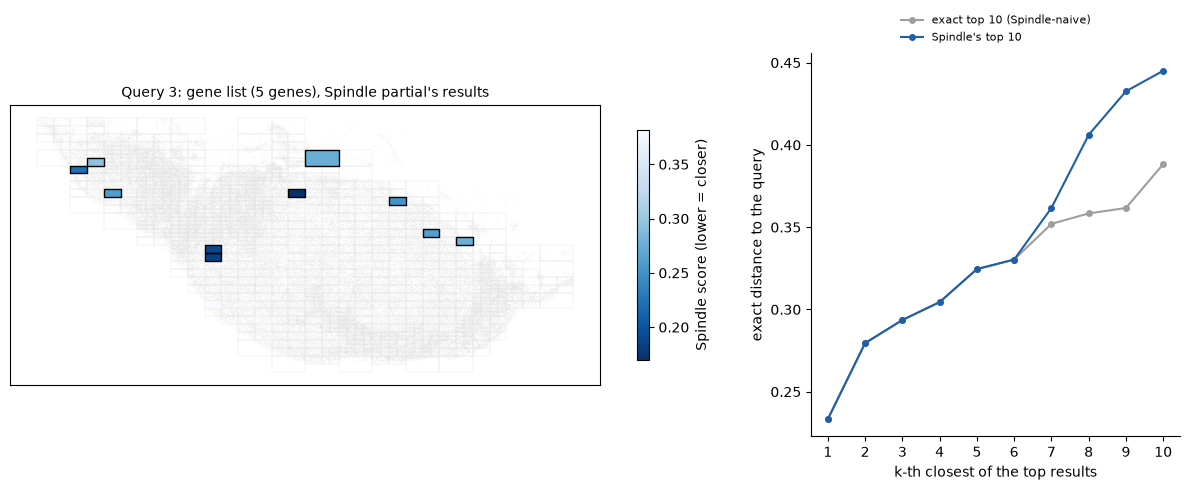

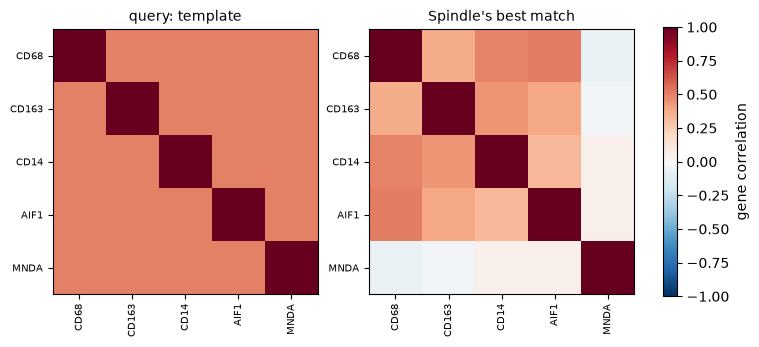

In [9]:
cov3, idx3 = sd.template_query(omega, idx)

rows3, scores3, sec3 = spindle_partial.search(cov3, idx3)
d3 = naive_partial.distances(cov3, idx3)                  # exact d_B^S to every index tile (reference)
summary("Gene list", rows3, d3, sec3, spindle_partial.last_stats)

show_query(rows3, scores3, d3, f"Query 3: gene list ({len(idx3)} genes), Spindle partial's results")
show_corr_pair(cov3, as_cov(train_covs[rows3[0]])[np.ix_(idx3, idx3)], genes[idx3], "query: template")

## 6. Save the indexes (optional)

The pickles can be reloaded with `sd.load_index`. To answer gene-list queries later, keep `omega` beside the
indexes (Spindle partial stores no tile covariances).

In [10]:
if OUT_DIR is not None:
    out = Path(OUT_DIR)
    out.mkdir(parents=True, exist_ok=True)
    data.spd_matrices, data.U_list = [], None              # drop the covariances from the layout before saving
    for name, obj in [("layout", data), ("spindle", spindle), ("spindle_partial", spindle_partial),
                      ("naive", naive), ("naive_partial", naive_partial)]:
        sd.save_index(obj, out / f"{path.stem}_{name}.pkl")
    np.save(out / f"{path.stem}_omega.npy", omega)
    print("saved to", out.resolve())